In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

# Load the uploaded CSV
file_name = "mandi_price.csv"

df = pd.read_csv(file_name)

# Preserve the original data
df_raw = df.copy()

print("Original dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Original dataset shape: (10962, 10)

Column names:
['State', 'District', 'Market', 'Commodity', 'Variety', 'Grade', 'Arrival_Date', 'Min_x0020_Price', 'Max_x0020_Price', 'Modal_x0020_Price']


,State,District,Market,Commodity,Variety,Grade,Arrival_Date,Min_x0020_Price,Max_x0020_Price,Modal_x0020_Price
0,Odisha,Mayurbhanja,Baripada APMC,Bitter gourd,Bitter Gourd,Medium,27/10/2026,5000.0,6000.0,5500.0
1,Odisha,Mayurbhanja,Baripada APMC,Tomato,Tomato,Medium,27/10/2026,3000.0,4000.0,3500.0
2,Chattisgarh,Khairagarh Chhuikhadan Gandai,Kheragarh APMC,Soyabean,Soyabeen,Non-FAQ,27/10/2026,5200.0,5400.0,5300.0
3,Andhra Pradesh,Prakasam,Maddipadu APMC,Bengal Gram(Gram)(Whole),Gulabi,FAQ,27/10/2026,6000.0,6000.0,6000.0
4,Telangana,Asifabad,Kagaznagar APMC,Paddy(Common),Paddy,Grade Range-1,27/10/2026,3500.0,3500.0,3500.0


In [2]:
#Standardized column name
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print("Standardised columns:")
print(df.columns.tolist())

Standardised columns:
['state', 'district', 'market', 'commodity', 'variety', 'grade', 'arrival_date', 'min_x0020_price', 'max_x0020_price', 'modal_x0020_price']


In [3]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows found:", duplicate_count)

# Remove exact duplicate rows
df = df.drop_duplicates().copy()

print("Shape after duplicate removal:", df.shape)

Duplicate rows found: 0
Shape after duplicate removal: (10962, 10)


In [4]:
# Identify likely date column
date_candidates = [
    col for col in df.columns
    if "date" in col or "arrival" in col
]

# Identify likely price columns
price_candidates = [
    col for col in df.columns
    if "price" in col or "modal" in col
]

print("Possible date columns:", date_candidates)
print("Possible price columns:", price_candidates)
# Convert the date column
if date_candidates:
    date_col = date_candidates[0]

    df[date_col] = pd.to_datetime(
        df[date_col],
        errors="coerce",
        dayfirst=True
    )

    print("Invalid or missing dates:", df[date_col].isna().sum())

for col in price_candidates:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(",", "", regex=False),
        errors="coerce"
    )

print("Price columns converted:", price_candidates)
display(df[price_candidates].describe().T)

Possible date columns: ['arrival_date']
Possible price columns: ['min_x0020_price', 'max_x0020_price', 'modal_x0020_price']
Invalid or missing dates: 0
Price columns converted: ['min_x0020_price', 'max_x0020_price', 'modal_x0020_price']


,count,mean,std,min,25%,50%,75%,max
min_x0020_price,10962.0,5146.653458,4802.813078,0.01,2500.0,4000.0,6000.0,90000.0
max_x0020_price,10962.0,5879.376192,5346.107091,0.01,3000.0,4500.0,7000.0,100000.0
modal_x0020_price,10962.0,5524.297685,5042.626461,0.01,2800.0,4250.0,6500.0,95000.0


In [5]:
# Missing-value report
missing_report = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (df.isna().mean() * 100).round(2)
}).sort_values("Missing_Percentage", ascending=False)

display(missing_report)

# Check for zero or negative prices
for col in price_candidates:
    invalid_price_count = (df[col].notna() & (df[col] <= 0)).sum()
    print(f"{col}: {invalid_price_count} zero or negative values")

,Missing_Count,Missing_Percentage
state,0,0.0
district,0,0.0
market,0,0.0
commodity,0,0.0
variety,0,0.0
grade,0,0.0
arrival_date,0,0.0
min_x0020_price,0,0.0
max_x0020_price,0,0.0
modal_x0020_price,0,0.0


min_x0020_price: 0 zero or negative values
max_x0020_price: 0 zero or negative values
modal_x0020_price: 0 zero or negative values


In [6]:
from pathlib import Path

output_dir = Path("/content/processed")
output_dir.mkdir(parents=True, exist_ok=True)

cleaned_file = output_dir / "mandi_prices_cleaned.csv"

df.to_csv(cleaned_file, index=False)

print("Cleaned dataset saved:", cleaned_file)
print("Final dataset shape:", df.shape)

from google.colab import files

files.download("/content/processed/mandi_prices_cleaned.csv")

Cleaned dataset saved: /content/processed/mandi_prices_cleaned.csv
Final dataset shape: (10962, 10)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

###EDA

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from pathlib import Path

uploaded = files.upload()
file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

# Standardise column names
df.columns = df.columns.str.strip()

# Determine if columns are in lowercase (already standardized) or original casing
is_lowercased = "arrival_date" in df.columns

date_col = "arrival_date" if is_lowercased else "Arrival_Date"
price_cols = [
    "min_x0020_price" if is_lowercased else "Min_x0020_Price",
    "max_x0020_price" if is_lowercased else "Max_x0020_Price",
    "modal_x0020_price" if is_lowercased else "Modal_x0020_Price"
]
text_cols = [
    "state" if is_lowercased else "State",
    "district" if is_lowercased else "District",
    "market" if is_lowercased else "Market",
    "commodity" if is_lowercased else "Commodity",
    "variety" if is_lowercased else "Variety",
    "grade" if is_lowercased else "Grade"
]

# Convert date and price columns
df[date_col] = pd.to_datetime(
    df[date_col],
    errors="coerce"
)

for col in price_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Standardise text fields
for col in text_cols:
    df[col] = df[col].astype("string").str.strip()

# Remove exact duplicate records
df = df.drop_duplicates().copy()

print("Cleaned dataset shape:", df.shape)
print("Missing values:\n", df.isnull().sum())
print("Date range:", df[date_col].min(), "to", df[date_col].max())

display(df.head())

Saving mandi_prices_cleaned (1).csv to mandi_prices_cleaned (1) (1).csv
Cleaned dataset shape: (10962, 10)
Missing values:
 state                0
district             0
market               0
commodity            0
variety              0
grade                0
arrival_date         0
min_x0020_price      0
max_x0020_price      0
modal_x0020_price    0
dtype: int64
Date range: 2026-10-27 00:00:00 to 2026-10-27 00:00:00


,state,district,market,commodity,variety,grade,arrival_date,min_x0020_price,max_x0020_price,modal_x0020_price
0,Odisha,Mayurbhanja,Baripada APMC,Bitter gourd,Bitter Gourd,Medium,2026-10-27,5000.0,6000.0,5500.0
1,Odisha,Mayurbhanja,Baripada APMC,Tomato,Tomato,Medium,2026-10-27,3000.0,4000.0,3500.0
2,Chattisgarh,Khairagarh Chhuikhadan Gandai,Kheragarh APMC,Soyabean,Soyabeen,Non-FAQ,2026-10-27,5200.0,5400.0,5300.0
3,Andhra Pradesh,Prakasam,Maddipadu APMC,Bengal Gram(Gram)(Whole),Gulabi,FAQ,2026-10-27,6000.0,6000.0,6000.0
4,Telangana,Asifabad,Kagaznagar APMC,Paddy(Common),Paddy,Grade Range-1,2026-10-27,3500.0,3500.0,3500.0


In [11]:
# Determine correct column keys based on the casing in the current dataframe
is_lowercased = "arrival_date" in df.columns

min_col = "min_x0020_price" if is_lowercased else "Min_x0020_Price"
max_col = "max_x0020_price" if is_lowercased else "Max_x0020_Price"
modal_col = "modal_x0020_price" if is_lowercased else "Modal_x0020_Price"
date_col = "arrival_date" if is_lowercased else "Arrival_Date"
state_col = "state" if is_lowercased else "State"
market_col = "market" if is_lowercased else "Market"
commodity_col = "commodity" if is_lowercased else "Commodity"

# Flag suspicious records instead of deleting them automatically
df["invalid_price"] = (
    (df[min_col] < 0)
    | (df[max_col] < 0)
    | (df[modal_col] < 0)
    | (df[min_col] > df[max_col])
    | (df[modal_col] < df[min_col])
    | (df[modal_col] > df[max_col])
)

print("Suspicious price records:", df["invalid_price"].sum())

# If there are suspicious records, show them; otherwise show a sample of clean records
if df["invalid_price"].sum() > 0:
    display(
        df.loc[df["invalid_price"],
               [state_col, market_col, commodity_col,
                date_col, min_col, modal_col, max_col]]
    )
else:
    print("\nAll records are valid! Here is a sample of the cleaned data:")

# Keep valid price records for analysis
df_clean = df.loc[~df["invalid_price"]].copy()
print("Records retained:", len(df_clean))
display(df_clean[[state_col, market_col, commodity_col, date_col, min_col, modal_col, max_col]].head(10))

Suspicious price records: 0

All records are valid! Here is a sample of the cleaned data:
Records retained: 10962


,state,market,commodity,arrival_date,min_x0020_price,modal_x0020_price,max_x0020_price
0,Odisha,Baripada APMC,Bitter gourd,2026-10-27,5000.0,5500.0,6000.0
1,Odisha,Baripada APMC,Tomato,2026-10-27,3000.0,3500.0,4000.0
2,Chattisgarh,Kheragarh APMC,Soyabean,2026-10-27,5200.0,5300.0,5400.0
3,Andhra Pradesh,Maddipadu APMC,Bengal Gram(Gram)(Whole),2026-10-27,6000.0,6000.0,6000.0
4,Telangana,Kagaznagar APMC,Paddy(Common),2026-10-27,3500.0,3500.0,3500.0
5,Telangana,RYTHU BAZAR FALAKNUMA,Bitter gourd,2026-10-27,3100.0,3100.0,3100.0
6,Telangana,RYTHU BAZAR FALAKNUMA,Cauliflower,2026-10-27,1800.0,1800.0,1800.0
7,Telangana,RYTHU BAZAR FALAKNUMA,Onion,2026-10-27,4000.0,4000.0,4000.0
8,Telangana,RYTHU BAZAR FALAKNUMA,Potato,2026-10-27,2300.0,2300.0,2300.0
9,Telangana,RYTHU BAZAR FALAKNUMA,Cluster beans,2026-10-27,3500.0,3500.0,3500.0


#Filter Maharashtra onion prices

Found 12 onion price records in Maharashtra.



,district,market,median_modal_price,average_modal_price,minimum_price,maximum_price,records,varieties
2,Nagpur,APMC Kamthi,5650.0,5650.0,5000.0,6000.0,1,1
10,Pune,Pune(Pimpri),4100.0,4100.0,4000.0,4200.0,1,1
5,Nashik,Lasalgaon(Niphad),4100.0,4100.0,1500.0,4300.0,1,1
4,Nashik,APMC Pimpalgaon Baswant,4100.0,4100.0,1500.0,5200.0,1,1
6,Nashik,Lasalgaon(Vinchur),4050.0,4050.0,1500.0,4516.0,1,1
3,Nashik,APMC Manmad,4000.0,4000.0,1500.0,4500.0,1,1
1,Mumbai,Mumbai-Onion & Potato Market,3800.0,3800.0,2800.0,4800.0,1,1
0,Ahilyanagar,APMC Karjat,3600.0,3600.0,3000.0,4200.0,1,1
11,Satara,APMC Vai,3500.0,3500.0,2000.0,5000.0,1,1
9,Pune,Pune(Moshi),3000.0,3000.0,2000.0,4000.0,1,1


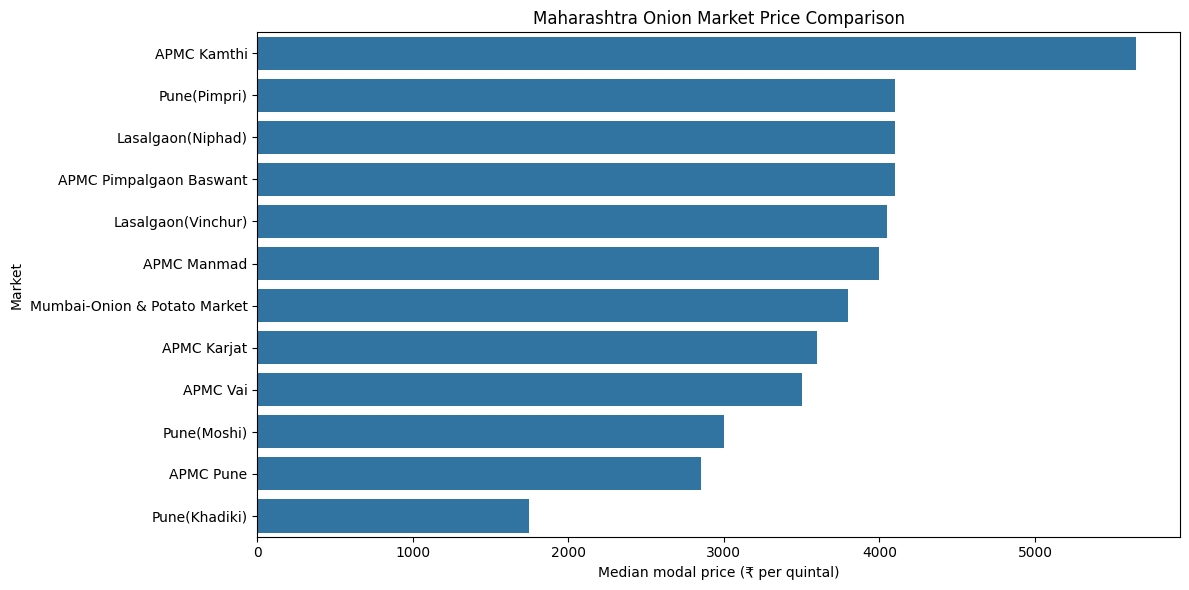

In [14]:
# Define the dynamic column helpers based on casing
is_lowercased = "arrival_date" in df_clean.columns

state_col = "state" if is_lowercased else "State"
commodity_col = "commodity" if is_lowercased else "Commodity"
district_col = "district" if is_lowercased else "District"
market_col = "market" if is_lowercased else "Market"
variety_col = "variety" if is_lowercased else "Variety"

# Create the missing onion_mh DataFrame by filtering df_clean
# We filter state for "Maharashtra" (case-insensitive) and commodity for "Onion" (case-insensitive)
onion_mh = df_clean[
    (df_clean[state_col].str.lower() == "maharashtra") &
    (df_clean[commodity_col].str.lower() == "onion")
].copy()

print(f"Found {len(onion_mh)} onion price records in Maharashtra.\n")

# Aggregate using the correct dynamic column names
market_summary = (
    onion_mh.groupby([district_col, market_col])
    .agg(
        median_modal_price=(modal_col, "median"),
        average_modal_price=(modal_col, "mean"),
        minimum_price=(min_col, "min"),
        maximum_price=(max_col, "max"),
        records=(modal_col, "count"),
        varieties=(variety_col, "nunique")
    )
    .reset_index()
    .sort_values("median_modal_price", ascending=False)
)

display(market_summary)

if not market_summary.empty:
    plt.figure(figsize=(12, 6))
    sns.barplot(
        data=market_summary,
        x="median_modal_price",
        y=market_col
    )
    plt.title("Maharashtra Onion Market Price Comparison")
    plt.xlabel("Median modal price (₹ per quintal)")
    plt.ylabel("Market")
    plt.tight_layout()
    plt.show()

,commodity,median_modal_price,average_modal_price,market_count,record_count
170,Tube Flower,85000.0,88333.333333,3,3
22,Black pepper,68000.0,57666.666667,3,3
59,Ghee,58300.0,58300.000000,1,1
81,Jasmine,57500.0,54153.846154,13,13
85,Kakada,45000.0,43857.142857,7,7
39,Coconut Oil,27150.0,27150.000000,2,2
12,Beaten Rice,26000.0,26000.000000,1,1
47,Cummin Seed(Jeera),23562.5,23388.750000,8,8
111,Mushroom,23500.0,22637.096774,31,31
4,Arecanut(Betelnut/Supari),23200.0,28119.272727,6,11


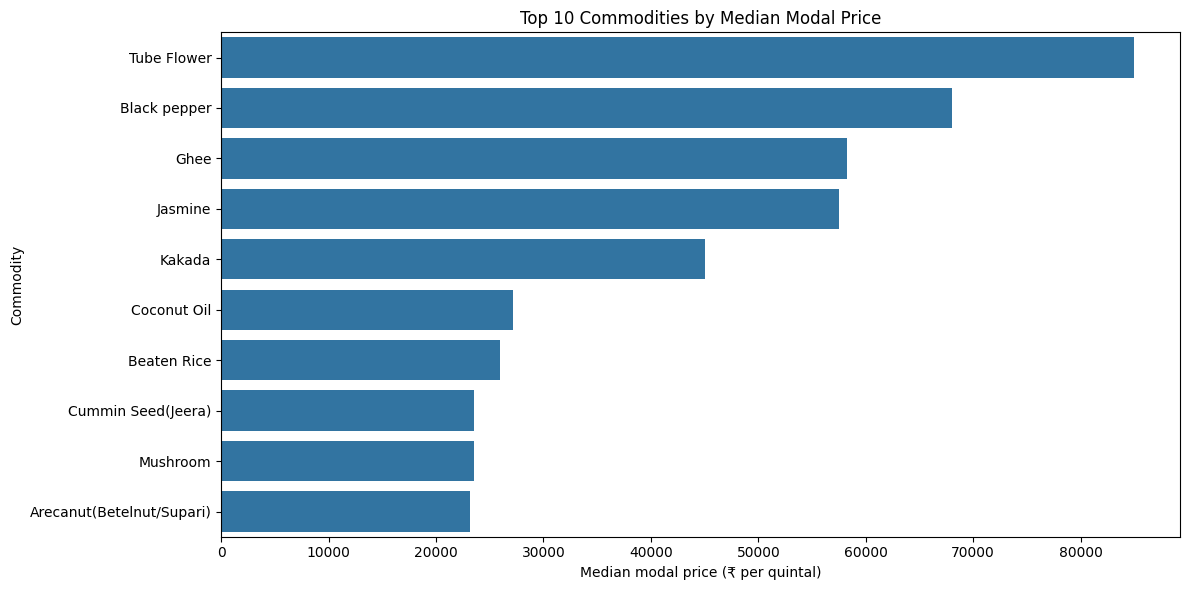

In [16]:
# Determine correct column keys based on the casing in the current dataframe
is_lowercased = "arrival_date" in df_clean.columns

commodity_col = "commodity" if is_lowercased else "Commodity"
market_col = "market" if is_lowercased else "Market"
modal_col = "modal_x0020_price" if is_lowercased else "Modal_x0020_Price"

commodity_summary = (
    df_clean.groupby(commodity_col)
    .agg(
        median_modal_price=(modal_col, "median"),
        average_modal_price=(modal_col, "mean"),
        market_count=(market_col, "nunique"),
        record_count=(modal_col, "count")
    )
    .reset_index()
    .sort_values("median_modal_price", ascending=False)
)

display(commodity_summary.head(15))

top_commodities = commodity_summary.head(10)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_commodities,
    x="median_modal_price",
    y=commodity_col
)
plt.title("Top 10 Commodities by Median Modal Price")
plt.xlabel("Median modal price (₹ per quintal)")
plt.ylabel("Commodity")
plt.tight_layout()
plt.show()

In [17]:
output_dir = Path("/content/processed")
output_dir.mkdir(parents=True, exist_ok=True)

df_clean.to_csv(
    output_dir / "mandi_prices_cleaned.csv",
    index=False
)

market_summary.to_csv(
    output_dir / "maharashtra_onion_market_summary.csv",
    index=False
)

commodity_summary.to_csv(
    output_dir / "india_commodity_summary.csv",
    index=False
)

print("Files saved:")
for path in output_dir.iterdir():
    print(path.name)

Files saved:
india_commodity_summary.csv
mandi_prices_cleaned.csv
maharashtra_onion_market_summary.csv


In [18]:
import sqlite3
from pathlib import Path

# Create project output folder
output_dir = Path("/content/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Create SQLite database
db_path = output_dir / "mandi_intelligence.db"
conn = sqlite3.connect(db_path)

# Load cleaned data into SQLite
df_clean.to_sql(
    "mandi_prices",
    conn,
    if_exists="replace",
    index=False
)

print("Database created:", db_path)
print("Table created: mandi_prices")

Database created: /content/processed/mandi_intelligence.db
Table created: mandi_prices
